# 01 — Exploratory Data Analysis (C-MAPSS FD001)

**Objective:**
Understand the degradation behavior of turbofan engines in the FD001 dataset.

**Questions to answer today:**
1. Are there dead/constant sensors that carry zero variance?
2. How long do engines typically survive before failure?
3. How do sensor values change over time as an engine approaches breakdown?
4. How do we compute the Remaining Useful Life (RUL) target?

## 1. Imports and Setup

In [2]:
import sys
from pathlib import Path

# Ensure project root is in sys.path so we can import from src
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data.loader import load_data

# Set visual style
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 6)

## 2. Load the Raw Training Data (FD001)

In [3]:
# Load FD001 train set using the function you wrote
df_train = load_data("train_FD001.txt")
print(f"Dataset shape: {df_train.shape}")
print(f"Number of unique engines: {df_train['engine_id'].nunique()}")
df_train.head()

Dataset shape: (20631, 26)
Number of unique engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Finding Dead Sensors (Zero-Variance Features)

In industrial telemetry, some sensors provide constant baseline references with standard deviation = 0.
Let's identify and list all columns that have zero variance so we know what to drop.

In [10]:
# Compute standard deviation for all sensor columns
# Hint: check df_train.describe() or df_train.std()
stds = df_train.std()
zero_std_cols = stds[stds == 0].index.tolist()
print("Dead / Constant columns:")
print(zero_std_cols)
df_train[zero_std_cols].describe()
constant_cols = [col for col in df_train.columns if df_train[col].nunique() == 1]
print(constant_cols)
# Drop constant columns from our EDA dataframe
df_train = df_train.drop(columns=constant_cols)
print(f"New dataframe shape: {df_train.shape}")

Dead / Constant columns:
['setting_3', 'sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']
['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
New dataframe shape: (20631, 19)


## 4. Compute the RUL (Remaining Useful Life) Target

For each engine, every row represents an operational cycle.
The engine fails at its maximum cycle ($T_{\text{max}}$).

$$\text{RUL}_{i, t} = T_{\text{max}, i} - t$$

Let's calculate this target column for `df_train`.

In [12]:
# Step 1 & 2: Calculate max cycle for each engine and broadcast it across rows
max_cycle_per_engine = df_train.groupby("engine_id")["cycle"].transform("max")

# Step 3: RUL = max cycle - current cycle
df_train["RUL"] = max_cycle_per_engine - df_train["cycle"]

# Verify for Engine 1: first 5 rows and last 5 rows
print("Engine 1 — Initial cycles (healthy):")
display(df_train[df_train["engine_id"] == 1][["engine_id", "cycle", "RUL"]].head())

print("Engine 1 — Final cycles (failure):")
display(df_train[df_train["engine_id"] == 1][["engine_id", "cycle", "RUL"]].tail())

Engine 1 — Initial cycles (healthy):


,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


Engine 1 — Final cycles (failure):


,engine_id,cycle,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


## 5. Visualizing Engine Lifespans

What is the distribution of engine lifetimes? Do all engines fail around the same cycle, or is there wide variance?

Shortest engine lifespan: 128 cycles (Engine 39)
Longest engine lifespan:  362 cycles (Engine 69)
Average engine lifespan:  206.3 cycles


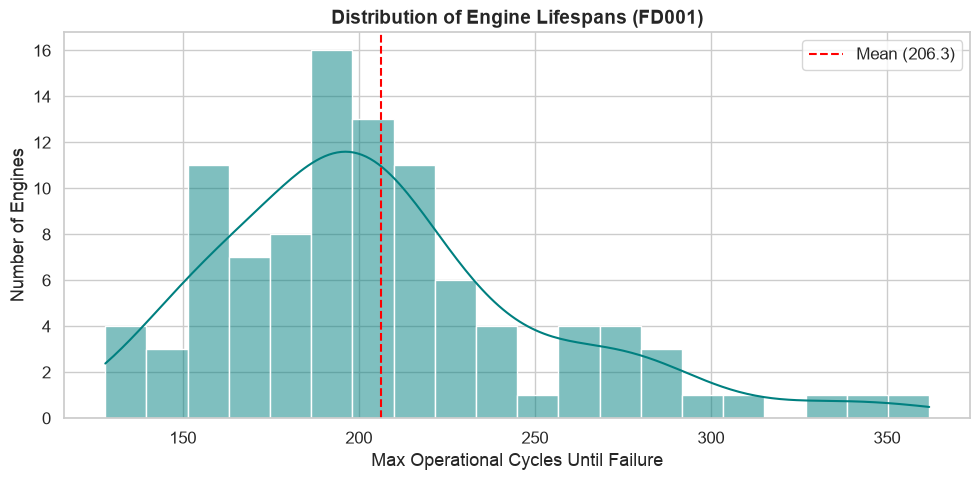

In [13]:
# Plot a histogram / KDE of max cycle per engine
# Group by engine to get each engine's lifespan (max cycle reached)
lifespans = df_train.groupby("engine_id")["cycle"].max()

print(f"Shortest engine lifespan: {lifespans.min()} cycles (Engine {lifespans.idxmin()})")
print(f"Longest engine lifespan:  {lifespans.max()} cycles (Engine {lifespans.idxmax()})")
print(f"Average engine lifespan:  {lifespans.mean():.1f} cycles")

# Plot distribution
plt.figure(figsize=(10, 5))
sns.histplot(lifespans, kde=True, bins=20, color="teal")
plt.axvline(lifespans.mean(), color="red", linestyle="--", label=f"Mean ({lifespans.mean():.1f})")
plt.title("Distribution of Engine Lifespans (FD001)", fontsize=14, fontweight="bold")
plt.xlabel("Max Operational Cycles Until Failure")
plt.ylabel("Number of Engines")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Visualizing Sensor Degradation Over Time

Pick a couple of active sensors (e.g. sensor_2, sensor_4, sensor_7, sensor_11, sensor_12) and plot their values over cycles for 3-4 sample engines (e.g. Engine 1, 2, 3).
Notice how sensor curves evolve as RUL approaches 0.

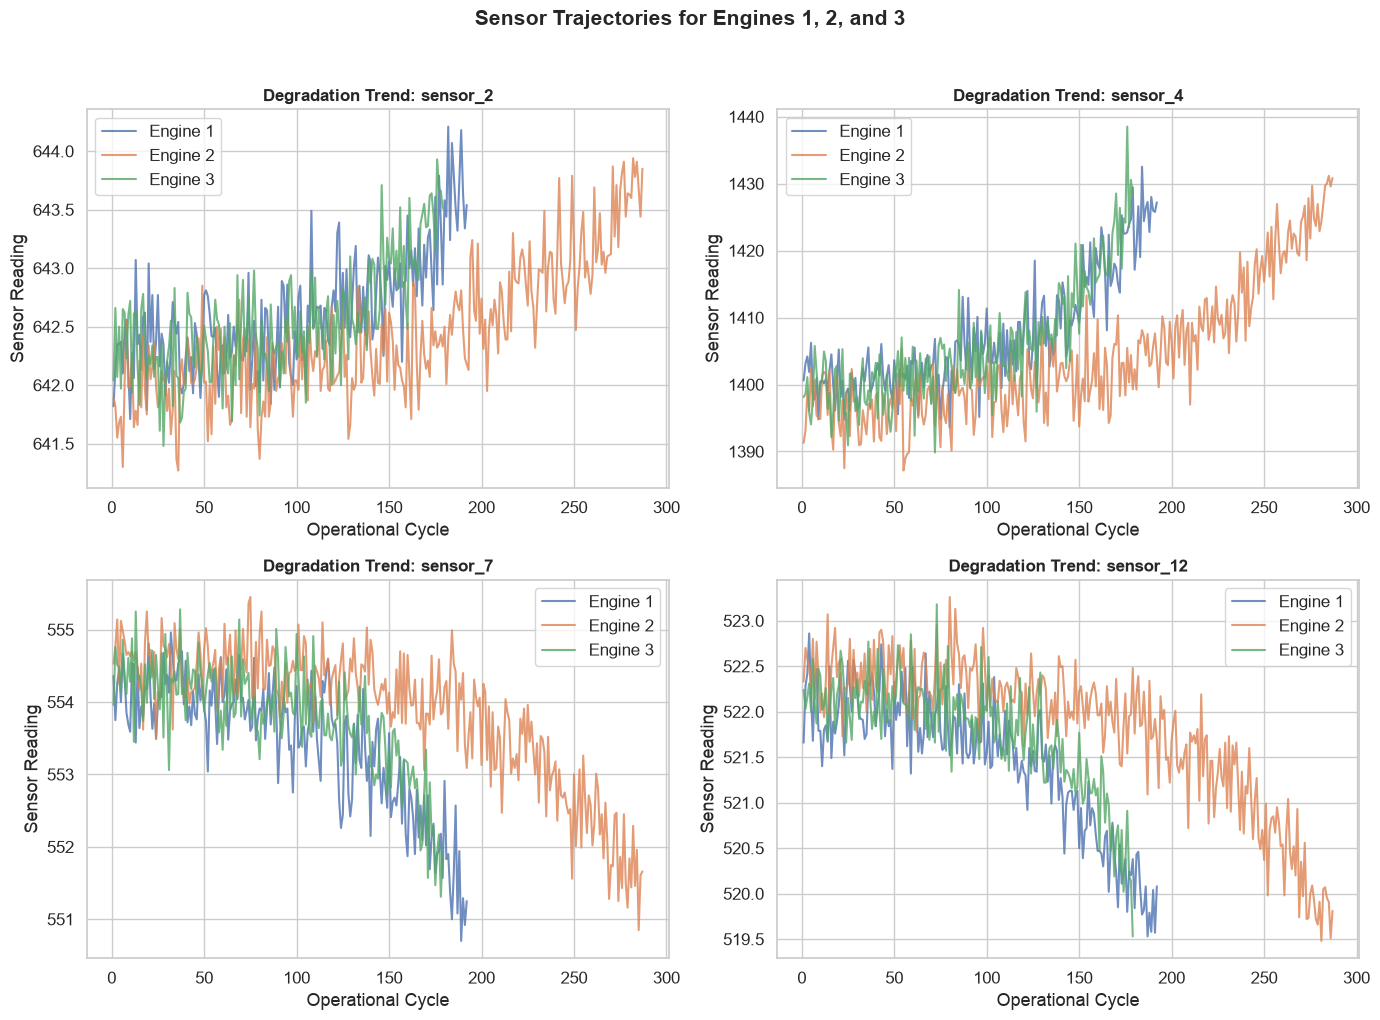

In [16]:
# Plot degradation curves over cycles for selected engines
# Sample 3 different engines
sample_engines = [1, 2, 3]
sensors_to_plot = ["sensor_2", "sensor_4", "sensor_7", "sensor_12"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=False)
axes = axes.flatten()

for i, sensor in enumerate(sensors_to_plot):
    ax = axes[i]
    for engine_id in sample_engines:
        engine_data = df_train[df_train["engine_id"] == engine_id]
        ax.plot(engine_data["cycle"], engine_data[sensor], label=f"Engine {engine_id}", alpha=0.8)
    
    ax.set_title(f"Degradation Trend: {sensor}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Operational Cycle")
    ax.set_ylabel("Sensor Reading")
    ax.legend()

plt.suptitle("Sensor Trajectories for Engines 1, 2, and 3", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()
